# Sentinel-2 U-Net flood mapping (pretrained WorldFloods)

Optical flood extent for the AOI in `layer_config.py`. This notebook is independent of `processing/pipeline.py` and of the Sentinel-1 UI tab.

**Logical proposition:** flood = Sentinel-2 **U-Net water** on the event scene, **minus** permanent water (WorldCover 80 + JRC occurrence + DEM-nodata sea), on **low and flat** ground.

| Step | What happens |
|---|---|
| 1. Display | Lab 2 SR composite (`S2_SR_HARMONIZED`, QA60, `CLOUDY_PIXEL_PERCENTAGE < 10`, median) + McFeeters NDWI |
| 2. Ancillary | FABDEM, WorldCover 2021, JRC GSW (same baselines as the Sentinel-1 notebook) |
| 3. U-Net input | One **L1C** scene (`COPERNICUS/S2_HARMONIZED`) closest **on or after** `FLOOD_PEAK_DATE`; bands B2, B3, B4, B8, B11, B12 |
| 4. Classifier | Pretrained **sm_unet_s2** (U-Net + MobileNetV2) from Hugging Face `isp-uv-es/udl4fl_models`, trained on WorldFloods + S1S2Water |
| 5. Flood | event water AND NOT permanent AND elevation/slope |
| 6. Output | geemap layers, area table, GeoTIFFs under `notebooks/_s2_unet_cache/` |

**Why L1C for the U-Net and SR for the map:** Lab 2 display uses surface reflectance. The open flood checkpoint was trained on **L1C TOA** (DN ≈ reflectance × 10000). Feeding SR into that network would be a domain shift.

**Why not Lab 5 training:** Lab 5 is a 6-band U-Net with ImageNet encoder weights and a short local train. This notebook **does not retrain**. It loads Portalés-Julià et al. (2025), *Remote Sensing of Environment*.

**Storm clouds:** The event scene is the first L1C **on or after** `FLOOD_PEAK_DATE`, even if cloudy. Do not swap it for a clearer image later in the week.

One-off install (PyTorch is not in the default Sentinel-1 UI environment):

```bash
uv add --group s2-unet torch segmentation-models-pytorch huggingface-hub geedim localtileserver
uv sync --group s2-unet
```


In [1]:
%matplotlib inline
import sys
from pathlib import Path

import ee
import geemap

_root = Path.cwd()
_nb = _root / "notebooks" if (_root / "notebooks" / "layer_config.py").exists() else _root
sys.path.insert(0, str(_nb))
import layer_config as cfg

_repo = _root if (_root / "processing" / "ee_auth.py").exists() else _root.parent
if str(_repo) not in sys.path:
    sys.path.insert(0, str(_repo))
from processing.ee_auth import initialize_ee

initialize_ee()

aoi = cfg.aoi_geometry()
print("GEE project:", cfg.GEE_PROJECT)
print("AOI:", cfg.MAP_CENTER, f"| rectangle ±{cfg.AOI_RADIUS_KM} km | bounds {cfg.AOI_BOUNDS}")
print("Dates:", cfg.START_DATE, "→", cfg.END_DATE)

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


GEE project: geog761-dongwook
AOI: [-39.58, 176.88] | rectangle ±5.0 km | bounds [176.82172378570127, -39.62491555874955, 176.93827621429872, -39.53508444125045]
Dates: 2023-02-12 → 2023-02-17


In [ ]:
def mask_s2_clouds(image):
    qa = image.select("QA60")
    cloud_bit = 1 << 10
    cirrus_bit = 1 << 11
    mask = qa.bitwiseAnd(cloud_bit).eq(0).And(qa.bitwiseAnd(cirrus_bit).eq(0))
    return image.updateMask(mask).divide(10000).select(["B2", "B3", "B4", "B8", "B11", "B12"])

s2_col = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(aoi)
    .filterDate(cfg.START_DATE, cfg.END_DATE)
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 99))
)
 

# Find the closest image to the flood peak date, but after peak date
flood_peak = ee.Date(cfg.FLOOD_PEAK_DATE)
s2_col_sorted = s2_col.filter(ee.Filter.gte("system:time_start", flood_peak.millis())).sort("system:time_start")
s2_image = s2_col_sorted.first()



n = s2_col_sorted.size().getInfo()
print("SR scenes after date / CLOUDY < 99 filter:", n)
if n == 0:
    print("No Lab-2-clear SR scenes in this window (typical in a cyclone). RGB/NDWI below is skipped; U-Net still uses L1C.")
else:
    info = s2_image.getInfo()
    print("First scene id:", info["id"])
    print("Scene cloud %:", info["properties"].get("CLOUDY_PIXEL_PERCENTAGE"))

SR scenes after date / CLOUDY < 30 filter: 2
First scene id: COPERNICUS/S2_SR_HARMONIZED/20230214T221559_20230214T221602_T60HVB
Scene cloud %: 77.333677


In [3]:
Map = geemap.Map(center=cfg.MAP_CENTER, zoom=cfg.MAP_ZOOM, basemap="HYBRID")
Map.addLayer(aoi, {"color": "red"}, "AOI")

if n > 0:
    s2 = mask_s2_clouds(s2_image).clip(aoi)
    ndwi = s2.normalizedDifference(["B3", "B8"]).rename("NDWI")
    rgb = {"bands": ["B4", "B3", "B2"], "min": 0, "max": 0.3}
    swir = {"bands": ["B12", "B8", "B4"], "min": 0, "max": 0.3}
    ndwi_vis = {"min": -0.5, "max": 0.5, "palette": ["brown", "white", "blue"]}
    Map.addLayer(s2, rgb, "S2 SR RGB (Lab 2)")
    Map.addLayer(s2, swir, "S2 SWIR-NIR-Red")
    Map.addLayer(ndwi, ndwi_vis, "NDWI")
else:
    s2 = None
    ndwi = None

Map

Map(center=[-39.58, 176.88], controls=(WidgetControl(options=['position', 'transparent_bg'], position='toprigh…

## 1b. Ancillary layers — DEM, WorldCover, JRC

Same permanent-water baseline as `01_sentinel1_layer.ipynb`. U-Net water on rivers, lakes, and sea is not flood until those classes are removed.

| Layer | Role |
|---|---|
| FABDEM | Bare-earth elevation and `ee.Terrain.slope`. Missing over open sea. |
| ESA WorldCover v200 (2021) | Class **80** = water / ocean. |
| JRC GSW `occurrence` | Pixels wet ≥ `PERMANENT_WATER_OCCURRENCE` % of the GSW record. |

`permanent_water` = WorldCover 80 **or** JRC high occurrence **or** DEM nodata (sea).


In [4]:
_fabdem = ee.ImageCollection("projects/sat-io/open-datasets/FABDEM").filterBounds(aoi)
dem = (
    _fabdem.mosaic()
    .select("b1")
    .setDefaultProjection(_fabdem.first().projection())
    .clip(aoi)
    .rename("elevation")
)
slope_deg = ee.Terrain.slope(dem).rename("slope")

worldcover = ee.Image("ESA/WorldCover/v200/2021").clip(aoi)
wc_water = worldcover.eq(80).rename("wc_water")

gsw = ee.Image("JRC/GSW1_4/GlobalSurfaceWater").clip(aoi)
gsw_permanent = gsw.select("occurrence").gte(cfg.PERMANENT_WATER_OCCURRENCE).unmask(0)
ocean_no_dem = dem.mask().Not().unmask(1)
permanent_water = gsw_permanent.Or(wc_water).Or(ocean_no_dem).rename("permanent_water")

elev_ok = dem.lt(cfg.ELEVATION_MAX_M).unmask(1).rename("elev_ok")
if cfg.ELEVATION_ABOVE_P5_M is not None:
    p5 = dem.reduceRegion(
        reducer=ee.Reducer.percentile([5]),
        geometry=aoi,
        scale=30,
        bestEffort=True,
        maxPixels=1e9,
    ).get("elevation")
    p5_val = ee.Number(p5).getInfo()
    print("DEM p5 (m):", p5_val)
    if p5_val is not None:
        elev_ok = elev_ok.And(dem.lte(ee.Number(p5_val).add(cfg.ELEVATION_ABOVE_P5_M))).rename("elev_ok")

slope_ok = slope_deg.lt(cfg.SLOPE_MAX_DEG).unmask(1).rename("slope_ok")
low_flat = elev_ok.And(slope_ok).rename("low_flat")

print("DEM:", dem.bandNames().getInfo())
print("ELEVATION_MAX_M:", cfg.ELEVATION_MAX_M, "| SLOPE_MAX_DEG:", cfg.SLOPE_MAX_DEG)
print("Permanent water = WorldCover 80 | JRC occurrence | DEM nodata (sea)")


DEM p5 (m): 0.1379042199779188
DEM: ['elevation']
ELEVATION_MAX_M: 25.0 | SLOPE_MAX_DEG: 10
Permanent water = WorldCover 80 | JRC occurrence | DEM nodata (sea)


## 2. L1C scenes nearest the flood peak (U-Net input)

The checkpoint `sm_unet_s2` expects **six L1C bands** in this order: Blue, Green, Red, NIR, SWIR1, SWIR2 (`B2`, `B3`, `B4`, `B8`, `B11`, `B12`). Values stay in native DN (about 0–10000), not `/10000`.

- **Event:** a **single** scene: the first L1C **on or after** `FLOOD_PEAK_DATE` (then `END_DATE`, then a short look-forward if that range is empty). Cloud metadata is printed but **not** used to pick a clearer later date.
- There is **no pre-event vs event comparison**. Permanent water (WorldCover / JRC / sea) is the baseline instead.


In [5]:
from datetime import date, timedelta

UNET_BANDS = ["B2", "B3", "B4", "B8", "B11", "B12"]


def l1c_col(geom, start, end):
    return (
        ee.ImageCollection("COPERNICUS/S2_HARMONIZED")
        .filterBounds(geom)
        .filterDate(start, end)
        .select(UNET_BANDS)
    )


def l1c_first(geom, start, end):
    """Single L1C scene: earliest in [start, end). Event only."""
    col = l1c_col(geom, start, end)
    n = col.size().getInfo()
    if n == 0:
        return None, {"start": start, "end": end, "id": None, "cloud_pct": None, "n": 0}
    img = ee.Image(col.sort("system:time_start").first())
    props = img.getInfo()["properties"]
    meta = {
        "start": start,
        "end": end,
        "id": props.get("system:index", "?"),
        "cloud_pct": props.get("CLOUDY_PIXEL_PERCENTAGE"),
        "n": n,
    }
    print(f"Event first on/after peak {start} → {end}: {n} L1C scene(s)")
    print(f"  using {meta['id']} | cloud {meta['cloud_pct']}%")
    return img.clip(geom), meta


peak = cfg.FLOOD_PEAK_DATE
end_d = date.fromisoformat(cfg.END_DATE)
s2_event, event_meta = None, None
for extra in (0, 10, 20):
    e = (end_d + timedelta(days=extra)).isoformat()
    s2_event, event_meta = l1c_first(aoi, peak, e)
    if s2_event is not None:
        break
assert s2_event is not None, (
    "No Sentinel-2 L1C on or after FLOOD_PEAK_DATE. Extend END_DATE in layer_config.py."
)

l1c_vis = {"bands": ["B4", "B3", "B2"], "min": 0, "max": 3000, "gamma": 1.1}
Map.addLayer(s2_event, l1c_vis, f"Event L1C RGB ({event_meta['id']})")
Map.addLayer(permanent_water.selfMask(), {"palette": ["#08306b"]}, "Permanent water", False)
Map


Event first on/after peak 2023-02-14 → 2023-02-17: 2 L1C scene(s)
  using 20230214T221559_20230214T221602_T60HVB | cloud 60.8698378572068%


Map(center=[-39.58, 176.88], controls=(WidgetControl(options=['position', 'transparent_bg'], position='toprigh…

## 3. Load pretrained U-Net (`sm_unet_s2`)

Weights: Hugging Face [`isp-uv-es/udl4fl_models`](https://huggingface.co/isp-uv-es/udl4fl_models) (`sm_unet_s2.pt`). The JSON says `unet`; the `.pt` keys are **U-Net++** (`decoder.blocks.x_i_j`) with a **MobileNetV2** encoder, 6 input channels, 2 classes (`land`, `water`). Mean/std come from `sm_unet_s2.json` (L1C DN).

CC BY-NC: non-commercial / coursework use only.


In [18]:
import json

import numpy as np
import torch
from huggingface_hub import hf_hub_download
import segmentation_models_pytorch as smp

HF_REPO = "isp-uv-es/udl4fl_models"
json_path = hf_hub_download(HF_REPO, "sm_unet_s2.json")
pt_path = hf_hub_download(HF_REPO, "sm_unet_s2.pt")
with open(json_path) as f:
    unet_cfg = json.load(f)

hp = unet_cfg["model_params"]["hyperparameters"]
norm = unet_cfg["model_params"]["normalization"]
S2_MEAN = np.array(norm["mean"]["S2"], dtype=np.float32)
S2_STD = np.array(norm["std"]["S2"], dtype=np.float32)
WATER_CLASS = 1  # label_names: land, water

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Encoder:", hp["encoder"], "| classes:", hp["num_classes"], "| S2 channels:", hp["num_channels"]["S2"])
print("L1C mean:", S2_MEAN.tolist())
print("L1C std:", S2_STD.tolist())

model = smp.UnetPlusPlus(
    encoder_name=hp["encoder"],
    encoder_weights=None,
    in_channels=int(hp["num_channels"]["S2"]),
    classes=int(hp["num_classes"]),
    activation=None,
)
ckpt = torch.load(pt_path, map_location=device, weights_only=False)
state = ckpt["state_dict"] if isinstance(ckpt, dict) and "state_dict" in ckpt else ckpt
if isinstance(state, dict) and len(state) == 1 and "model" in state:
    state = state["model"]

cleaned = {}
for key, val in state.items():
    name = key
    for prefix in ("model.model.", "network.", "model.", "net.", "module."):
        if name.startswith(prefix):
            name = name[len(prefix) :]
            break
    if name.startswith("loss") or name.startswith("criterion"):
        continue
    cleaned[name] = val

missing, unexpected = model.load_state_dict(cleaned, strict=False)
print("load_state_dict missing:", len(missing), "unexpected:", len(unexpected))
if missing:
    print("  missing sample:", missing[:8])
if unexpected:
    print("  unexpected sample:", unexpected[:8])
model.to(device)
model.eval()
print("Loaded", pt_path)


Device: cpu
Encoder: mobilenet_v2 | classes: 2 | S2 channels: 6
L1C mean: [3758.07470703125, 3238.08251953125, 3418.9013671875, 3981.962646484375, 2391.6611328125, 1790.324951171875]
L1C std: [2794.095703125, 2549.494140625, 2811.781005859375, 2500.478759765625, 1500.025390625, 1241.9818115234375]
load_state_dict missing: 0 unexpected: 0
Loaded /Users/dongwook.kim/.cache/huggingface/hub/models--isp-uv-es--udl4fl_models/snapshots/d50292174d5574deee6515a200515a028303071f/sm_unet_s2.pt


## 4. Download stacks and run sliding-window inference

GEE images are pulled as 10 m GeoTIFFs into `notebooks/_s2_unet_cache/` (gitignored `*.tif`). Inference uses 256×256 tiles with overlap, reflection padding to a multiple of 32, softmax, and class 1 = water. Cloud/nodata in L1C is taken from a valid-pixel mask so those cells are not labelled flood.


In [19]:
from skimage.morphology import remove_small_objects
import rasterio
from rasterio.enums import Resampling

CACHE = _repo / "notebooks" / "_s2_unet_cache"
CACHE.mkdir(parents=True, exist_ok=True)

# Hawke's Bay is UTM 60S. Area stats need metres, not degrees.
event_crs = "EPSG:32760"
print("Download CRS:", event_crs)

ancillary = (
    dem.addBands(slope_deg)
    .addBands(permanent_water)
    .addBands(low_flat)
    .toFloat()
)


def download_clip(img, filename, bands=None):
    path = CACHE / filename
    src = img.select(bands) if bands else img
    geemap.download_ee_image(
        src,
        filename=str(path),
        region=aoi,
        scale=cfg.WORKING_SCALE,
        crs=event_crs,
    )
    print("Wrote", path, "bytes", path.stat().st_size)
    return path


event_tif = download_clip(s2_event, "event_l1c.tif", UNET_BANDS)
anc_tif = download_clip(ancillary, "ancillary.tif")


def read_chw(path):
    with rasterio.open(path) as src:
        arr = src.read().astype(np.float32)  # (C, H, W)
        profile = src.profile
        valid = np.all(np.isfinite(arr), axis=0) & np.any(arr != 0, axis=0)
    return arr, valid, profile


def predict_water_prob(chw, valid, tile=256, overlap=32):
    c, height, width = chw.shape
    x = (chw - S2_MEAN[:, None, None]) / (S2_STD[:, None, None] + 1e-6)
    x[:, ~valid] = 0.0
    prob = np.zeros((height, width), dtype=np.float32)
    weight = np.zeros((height, width), dtype=np.float32)
    step = max(tile - overlap, 1)
    for row in range(0, height, step):
        for col in range(0, width, step):
            r1 = min(row + tile, height)
            c1 = min(col + tile, width)
            r0 = max(0, r1 - tile)
            c0 = max(0, c1 - tile)
            patch = x[:, r0:r1, c0:c1]
            ph, pw = patch.shape[1], patch.shape[2]
            pad_h = (32 - ph % 32) % 32
            pad_w = (32 - pw % 32) % 32
            if pad_h or pad_w:
                patch = np.pad(patch, ((0, 0), (0, pad_h), (0, pad_w)), mode="reflect")
            tensor = torch.from_numpy(np.ascontiguousarray(patch[None])).to(device)
            with torch.no_grad():
                logits = model(tensor)
                water = torch.softmax(logits, dim=1)[0, WATER_CLASS].detach().cpu().numpy()
            water = water[:ph, :pw]
            prob[r0:r1, c0:c1] += water
            weight[r0:r1, c0:c1] += 1.0
    out = prob / np.maximum(weight, 1.0)
    out[~valid] = 0.0
    return out


event_chw, event_valid, event_profile = read_chw(event_tif)
event_prob = predict_water_prob(event_chw, event_valid)
event_water = (event_prob >= 0.6) & event_valid
print("Event water fraction:", float(event_water.mean()))


Download CRS: EPSG:32760


20230214T221559_20230214T221602_T60HVB:   0%|          |0/3 tiles [00:00<?]

Wrote /Users/dongwook.kim/UoA/GEOG761-GIS/notebooks/_s2_unet_cache/event_l1c.tif bytes 10023932


  0%|          |0/4 tiles [00:00<?]

Wrote /Users/dongwook.kim/UoA/GEOG761-GIS/notebooks/_s2_unet_cache/ancillary.tif bytes 2450977
Event water fraction: 0.38215606044291306


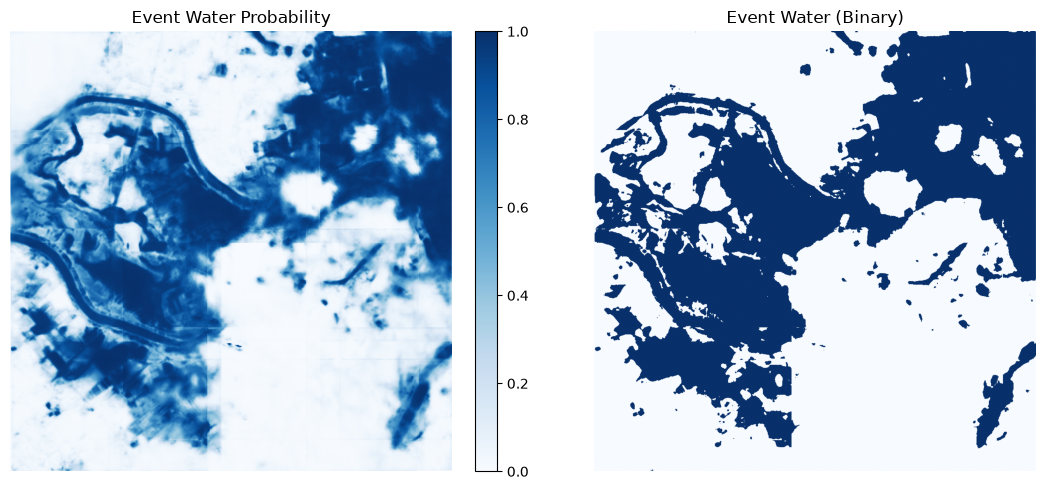


Generated TIF files:
Event scene: /Users/dongwook.kim/UoA/GEOG761-GIS/notebooks/_s2_unet_cache/event_l1c.tif
Ancillary data: /Users/dongwook.kim/UoA/GEOG761-GIS/notebooks/_s2_unet_cache/ancillary.tif


In [20]:
%matplotlib inline
# Display the generated water probability and flood maps
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im1 = axes[0].imshow(event_prob, cmap='Blues', vmin=0, vmax=1)
axes[0].set_title('Event Water Probability')
axes[0].axis('off')
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

axes[1].imshow(event_water, cmap='Blues')
axes[1].set_title('Event Water (Binary)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(f"\nGenerated TIF files:")
print(f"Event scene: {event_tif}")
print(f"Ancillary data: {anc_tif}")

## 5. Flood = event water − permanent − steep/high ground

MMU uses `MMU_PIXELS` from `layer_config.py` (connected water pixels at 10 m).


In [21]:
with rasterio.open(anc_tif) as src:
    anc = src.read(
        out_shape=(src.count, event_chw.shape[1], event_chw.shape[2]),
        resampling=Resampling.nearest,
    )
# ancillary bands: elevation, slope, permanent_water, low_flat
perm = anc[2] > 0.5
low = anc[3] > 0.5

inundation = event_water & (~perm) & low
final_flood = remove_small_objects(inundation, min_size=int(cfg.MMU_PIXELS))

flood_path = CACHE / "s2_unet_flood.tif"
profile = event_profile.copy()
profile.update(count=1, dtype="uint8", nodata=0, compress="lzw")
with rasterio.open(flood_path, "w", **profile) as dst:
    dst.write(final_flood.astype(np.uint8), 1)
print("Flood GeoTIFF:", flood_path)

px_h = abs(event_profile["transform"][4])
px_w = abs(event_profile["transform"][0])
px_km2 = (px_h * px_w) / 1e6
stats = {
    "aoi_km2": float(event_valid.sum() * px_km2),
    "event_unet_water_km2": float(event_water.sum() * px_km2),
    "permanent_water_km2": float(perm.sum() * px_km2),
    "inundation_before_mmu_km2": float(inundation.sum() * px_km2),
    "flood_final_km2": float(final_flood.sum() * px_km2),
    "event_scene": event_meta["id"],
    "event_cloud_pct": event_meta["cloud_pct"],
}
for key, val in stats.items():
    print(f"{key}: {val}")


Flood GeoTIFF: /Users/dongwook.kim/UoA/GEOG761-GIS/notebooks/_s2_unet_cache/s2_unet_flood.tif
aoi_km2: 99.97160000000001
event_unet_water_km2: 38.3301
permanent_water_km2: 8.052200000000001
inundation_before_mmu_km2: 30.9558
flood_final_km2: 30.925
event_scene: 20230214T221559_20230214T221602_T60HVB
event_cloud_pct: 60.8698378572068


## 6. Report figure (1×3)

(a) true colour, (b) U-Net water (probability ≥ 0.6), (c) final flood extent (permanent water and steep/high ground removed). Cloud is hatched where the s2cloudless probability for the same scene is ≥ 50% (`COPERNICUS/S2_CLOUD_PROBABILITY`). Same map furniture and flood colour as the Sentinel-1 figures. Saved to `outputs/sentinel2/s2_flood_figure.png`.

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from processing.map_furniture import FLOOD_COLOR, FLOOD_LABEL, add_north_arrow, add_scale_bar

CLOUD_PROB_MIN = 50          # s2cloudless probability (%) at or above which a pixel counts as cloud
WATER_COLOR = "#3a7dc9"
FIG_DIR = _repo / "outputs" / "sentinel2"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Cloud: s2cloudless probability for the same scene, sampled onto the event grid.
h, w = event_chw.shape[1:]
t, crs = event_profile["transform"], event_profile["crs"]
cloud_col = ee.ImageCollection("COPERNICUS/S2_CLOUD_PROBABILITY").filter(
    ee.Filter.eq("system:index", event_meta["id"]))
if cloud_col.size().getInfo():
    px = ee.data.computePixels({
        "expression": cloud_col.first().select(["probability"]).toFloat(),
        "fileFormat": "NUMPY_NDARRAY",
        "grid": {
            "dimensions": {"width": int(w), "height": int(h)},
            "affineTransform": {"scaleX": t.a, "shearX": t.b, "translateX": t.c,
                                "shearY": t.d, "scaleY": t.e, "translateY": t.f},
            "crsCode": crs.to_string(),
        },
    })
    cloud = (np.asarray(px["probability"], dtype=float) >= CLOUD_PROB_MIN) & event_valid
else:
    print("No s2cloudless image for this scene; cloud hatching skipped.")
    cloud = np.zeros((h, w), dtype=bool)
print(f"Cloud (s2cloudless ≥ {CLOUD_PROB_MIN}%): {cloud.sum() / max(event_valid.sum(), 1):.0%} of the scene")

when = ee.Date(s2_event.get("system:time_start")).format("d MMM YYYY, HH:mm").getInfo()
rgb = np.moveaxis(np.clip(event_chw[[2, 1, 0]] / 3000.0, 0, 1) ** (1 / 1.1), 0, -1)  # B4, B3, B2
km_per_px = abs(t.a) / 1000.0
cloud_patch = Patch(facecolor="white", edgecolor="0.2", hatch="////",
                    label=f"Cloud (s2cloudless ≥ {CLOUD_PROB_MIN}%)")


def hatch_cloud(ax):
    if cloud.any():
        ax.contourf(cloud.astype(float), levels=[0.5, 1.5], colors="none", hatches=["////"])
        ax.contour(cloud.astype(float), levels=[0.5], colors="0.2", linewidths=0.6)
    ax.set_xlim(-0.5, w - 0.5)
    ax.set_ylim(h - 0.5, -0.5)


with plt.rc_context({"hatch.color": "0.2", "hatch.linewidth": 0.6}):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.8), layout="constrained")
    for ax in axes:
        ax.imshow(rgb, interpolation="nearest")
    axes[1].imshow(np.ma.masked_where(~event_water, event_water), cmap=ListedColormap([WATER_COLOR]),
                   alpha=0.75, interpolation="nearest")
    axes[2].imshow(np.ma.masked_where(~final_flood, final_flood), cmap=ListedColormap([FLOOD_COLOR]),
                   interpolation="nearest")
    for ax in axes[1:]:
        hatch_cloud(ax)

    axes[0].set_title(f"(a) Sentinel-2 true colour, {when} UTC", loc="left")
    axes[1].set_title("(b) U-Net water probability ≥ 0.6", loc="left")
    axes[2].set_title("(c) Optical flood extent", loc="left")
    axes[1].legend(handles=[Patch(facecolor=WATER_COLOR, alpha=0.75, label="U-Net water"), cloud_patch],
                   loc="lower right", fontsize=9, framealpha=0.92)
    axes[2].legend(handles=[Patch(facecolor=FLOOD_COLOR, label=FLOOD_LABEL), cloud_patch],
                   loc="lower right", fontsize=9, framealpha=0.92)
    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])
        add_north_arrow(ax)
        add_scale_bar(ax, km_per_px)

    fig.savefig(FIG_DIR / "s2_flood_figure.png", dpi=300, bbox_inches="tight")
    plt.show()
print("Saved", FIG_DIR / "s2_flood_figure.png")

In [23]:
stats

{'aoi_km2': 99.97160000000001,
 'event_unet_water_km2': 38.3301,
 'permanent_water_km2': 8.052200000000001,
 'inundation_before_mmu_km2': 30.9558,
 'flood_final_km2': 30.925,
 'event_scene': '20230214T221559_20230214T221602_T60HVB',
 'event_cloud_pct': 60.8698378572068}

## Notes for the report

- The U-Net predicts **water**, not flood. Flood is event water after permanent water and DEM filters (no pre-event comparison).
- Event imagery may be days off the peak if the cyclone week is cloudy. Record `event_scene` and `event_cloud_pct` from the stats cell.
- Domain: the checkpoint is global WorldFloods + S1S2Water, not fine-tuned on Aotearoa. Shadows, turbid floodwater, and sunglint can still confuse it.
- Lab 5 is **not** used as a trained model here (ImageNet encoder only). This notebook loads the published flood U-Net.
- Do not wire this into `processing/pipeline.py` until the notebook run looks right on Gabrielle.
